# PT4 - 2409106002 - Renaya Putri Alika - KB
## Klasifikasi Citra Cat, Dog, dan Bird dengan CNN Custom

Notebook ini membangun model CNN untuk mengklasifikasikan gambar ke dalam **tiga kelas: Cat, Dog, dan Bird**. Dataset tetap menggunakan dataset Roboflow yang sudah dimiliki; program tidak menambahkan atau membuat kelas baru.

Alur notebook meliputi pemeriksaan environment, pemilihan dan ekstraksi ZIP, pemeriksaan jumlah gambar per kelas, visualisasi contoh gambar, preprocessing, augmentasi, pembangunan CNN custom, pelatihan dengan callbacks, grafik akurasi dan loss, evaluasi menggunakan confusion matrix serta classification report, dan penyimpanan model.

Jalankan sel secara berurutan dari atas ke bawah. Saat memilih dataset, gunakan file ZIP Roboflow yang memiliki folder `train` dan `valid`/`validasi`.

### Instalasi library
Sel ini memasang paket yang diperlukan agar notebook dapat dijalankan. `tensorflow` menyediakan fungsi untuk membangun dan melatih CNN, `scikit-learn` menyediakan metrik evaluasi, `pandas` membantu menyusun data, `matplotlib` membuat grafik, dan `numpy` mendukung pengolahan array. Jika paket sudah tersedia, pemasangan ulang biasanya tidak diperlukan. Jalankan sel ini pada environment Python yang akan digunakan untuk menjalankan notebook.

In [1]:
%pip install tensorflow scikit-learn pandas matplotlib numpy

Note: you may need to restart the kernel to use updated packages.


### Memeriksa environment
Sel ini menampilkan informasi interpreter Python, sistem operasi, dan versi TensorFlow. Informasi tersebut berguna untuk memastikan notebook berjalan pada environment yang benar serta membantu menelusuri masalah jika TensorFlow tidak dapat diimpor. Perhatikan lokasi Python yang digunakan, terutama jika komputer memiliki lebih dari satu instalasi Python.

In [2]:
# ============================================================
# CEK ENVIRONMENT PYTHON DAN TENSORFLOW
# ============================================================

import sys
import platform
import subprocess

print("=" * 50)
print("INFORMASI ENVIRONMENT")
print("=" * 50)

print("Lokasi Python :", sys.executable)
print("Versi Python  :", sys.version)
print("Sistem Operasi:", platform.platform())
print("Arsitektur Mac:", platform.machine())

print("\n" + "=" * 50)
print("PEMERIKSAAN TENSORFLOW")
print("=" * 50)

try:
    import tensorflow as tf
    print("TensorFlow berhasil ditemukan!")
    print("Versi TensorFlow:", tf.__version__)
except ImportError:
    print("TensorFlow belum terpasang di environment ini.")
    print("Jalankan perintah berikut di cell notebook:")
    print("%pip install tensorflow scikit-learn pandas matplotlib numpy")


INFORMASI ENVIRONMENT
Lokasi Python : /Users/renayaputri81gmail.com/.venv/bin/python
Versi Python  : 3.14.4 (main, Apr 14 2026, 14:46:33) [Clang 22.1.3 ]
Sistem Operasi: macOS-26.5.1-arm64-arm-64bit-Mach-O
Arsitektur Mac: arm64

PEMERIKSAAN TENSORFLOW
TensorFlow berhasil ditemukan!
Versi TensorFlow: 2.22.0-rc0


## 1. Persiapan library

Program membutuhkan beberapa library dengan fungsi yang berbeda. `TensorFlow` digunakan untuk membaca data gambar, menyusun arsitektur CNN, melatih model, dan menjalankan prediksi. `NumPy` membantu mengolah data numerik, sedangkan `Pandas` digunakan untuk menyusun riwayat pelatihan dalam bentuk tabel. `Matplotlib` dipakai untuk menampilkan gambar dan grafik hasil pelatihan. Sementara itu, fungsi evaluasi dari `scikit-learn` digunakan untuk membuat confusion matrix dan laporan klasifikasi.

Pada bagian berikutnya, library diimpor dan nilai acak diatur menggunakan seed agar beberapa proses acak, seperti pengacakan data, lebih konsisten ketika notebook dijalankan kembali.

### Mengimpor library dan mengatur seed
Sel ini mengimpor library yang digunakan pada tahapan selanjutnya. `pathlib`, `os`, dan `zipfile` membantu menangani folder serta file dataset; `random`, `numpy`, dan TensorFlow digunakan dalam pengaturan seed; `matplotlib` digunakan untuk visualisasi; dan fungsi dari `sklearn.metrics` dipakai saat evaluasi. Seed bernilai 42 ditetapkan pada beberapa generator acak agar hasil pengacakan lebih konsisten ketika notebook dijalankan kembali, meskipun hasil pelatihan masih dapat berbeda antarlingkungan.

In [3]:
import os
import pathlib
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.22.0-rc0


## 2. Memuat dataset

Bagian ini digunakan untuk memilih file ZIP dataset yang sudah diunduh dari Roboflow. Saat sel dijalankan di komputer lokal, jendela pemilihan file akan muncul sehingga file ZIP dapat dipilih tanpa perlu mengetik alamatnya secara manual. Setelah file dipilih, program mengekstrak isinya ke folder kerja yang ditentukan.

Pastikan file yang dipilih memang berisi dataset gambar Cat, Dog, dan Bird. Jika jendela pemilihan file tidak dapat digunakan pada lingkungan tertentu, periksa pesan yang ditampilkan dan sesuaikan lokasi file dataset secara manual.

### Memilih dan mengekstrak file ZIP
Sel ini membuka dialog pemilihan file untuk mencari ZIP dataset, kemudian mengekstrak arsip ke folder kerja. Program menggunakan `pathlib` untuk mengelola lokasi file dan `zipfile` untuk membuka arsip. Pilih ZIP hasil unduhan dataset, bukan folder gambar satuan. Setelah proses selesai, periksa pesan keluaran untuk memastikan lokasi ekstraksi sesuai dengan yang diharapkan.

In [4]:
# Memilih file dataset 
from pathlib import Path
import zipfile

try:
    import tkinter as tk
    from tkinter import filedialog

    window = tk.Tk()
    window.withdraw()
    window.attributes("-topmost", True)
    zip_path = filedialog.askopenfilename(
        title="Pilih ZIP dataset Cats, Dogs and Birds",
        filetypes=[("ZIP dataset", "*.zip")]
    )
    window.destroy()
except Exception as error:
    print("Jendela pemilihan file tidak dapat dibuka:", error)
    zip_path = input("Tempel path lengkap file ZIP dataset di sini: ").strip().strip("'").strip('"')

if not zip_path:
    raise ValueError(
        "Belum ada file ZIP yang dipilih. Jalankan ulang cell ini dan pilih file ZIP dataset."
    )

zip_path = Path(zip_path).expanduser()
if not zip_path.is_file():
    raise FileNotFoundError(f"File ZIP tidak ditemukan: {zip_path}")

DATASET_ROOT = Path.cwd() / "dataset"
DATASET_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(DATASET_ROOT)

print("Dataset berhasil diekstrak.")
print("File ZIP:", zip_path)
print("Folder hasil ekstraksi:", DATASET_ROOT)
print("Isi folder:", [p.name for p in DATASET_ROOT.iterdir()])


Dataset berhasil diekstrak.
File ZIP: /Users/renayaputri81gmail.com/Downloads/Cats- dogs and birds.v3i.folder.zip
Folder hasil ekstraksi: /Users/renayaputri81gmail.com/Documents/PRAKTIKUM_KB/POSTTEST/dataset
Isi folder: ['README.roboflow.txt', 'valid', 'README.dataset.txt', 'test', 'train', 'train 2']


## 3. Menentukan folder train, validasi, dan test

Dataset umumnya dipisahkan menjadi folder `train`, `valid`, dan `test`. Data training digunakan untuk memperbarui bobot model, data validasi membantu memantau kinerja selama pelatihan, sedangkan data test digunakan untuk mengukur kinerja akhir pada gambar yang tidak dipakai untuk memperbarui bobot.

Fungsi pada sel berikut menelusuri folder dataset untuk menemukan susunan folder tersebut. Nama subfolder kelas kemudian digunakan sebagai label gambar. Jika struktur folder dataset berbeda dari susunan yang diharapkan, periksa kembali hasil ekstraksi ZIP dan lokasi folder yang terdeteksi.

### Mencari lokasi folder data
Fungsi `find_split_root` menelusuri direktori dataset dan subdirektorinya untuk menemukan folder yang memiliki susunan `train`, `valid` atau `validation`, serta `test` bila tersedia. Pencarian ini membuat program lebih fleksibel terhadap ZIP yang memiliki satu folder induk tambahan. Hasil pencarian digunakan untuk menentukan lokasi data yang akan dibaca pada tahap berikutnya.

In [5]:
def find_split_root(root):
    if not root.exists():
        return None
    candidates = [root] + [p for p in root.rglob("*") if p.is_dir()]
    for folder in candidates:
        try:
            subdirs = {p.name.lower() for p in folder.iterdir() if p.is_dir()}
        except PermissionError:
            continue
        has_train = "train" in subdirs
        has_valid = bool({"valid", "val", "validation"} & subdirs)
        if has_train and has_valid:
            return folder
    return None

root_found = find_split_root(DATASET_ROOT)
if root_found is None:
    raise FileNotFoundError(
        "Folder train dan valid/val tidak ditemukan di dalam ZIP. "
        "Pastikan ZIP yang dipilih adalah dataset klasifikasi Roboflow "
        "yang memiliki folder train dan valid."
    )

DATASET_ROOT = root_found
TRAIN_DIR = DATASET_ROOT / "train"
VALID_DIR = next(
    DATASET_ROOT / name for name in ["valid", "val", "validation"]
    if (DATASET_ROOT / name).exists()
)
TEST_DIR = next(
    (DATASET_ROOT / name for name in ["test", "testing"]
     if (DATASET_ROOT / name).exists()),
    None
)

print("Dataset:", DATASET_ROOT)
print("Train:", TRAIN_DIR)
print("Validasi:", VALID_DIR)
print("Test:", TEST_DIR if TEST_DIR else "Tidak tersedia")


Dataset: /Users/renayaputri81gmail.com/Documents/PRAKTIKUM_KB/POSTTEST/dataset
Train: /Users/renayaputri81gmail.com/Documents/PRAKTIKUM_KB/POSTTEST/dataset/train
Validasi: /Users/renayaputri81gmail.com/Documents/PRAKTIKUM_KB/POSTTEST/dataset/valid
Test: /Users/renayaputri81gmail.com/Documents/PRAKTIKUM_KB/POSTTEST/dataset/test


## 4. Menghitung jumlah gambar setiap kelas

Sebelum model dilatih, jumlah file gambar pada tiga kelas—Cat, Dog, dan Bird—dihitung untuk melihat isi dataset. Program memeriksa ekstensi gambar yang umum digunakan, seperti JPG, JPEG, PNG, BMP, dan WEBP, lalu menjumlahkan file pada masing-masing folder kelas.

Hasil perhitungan ditampilkan sebagai tabel untuk bagian training, validasi, dan test apabila foldernya tersedia. Jumlah gambar yang berbeda jauh antarkelas dapat membuat model lebih sering mempelajari kelas yang memiliki lebih banyak contoh, sehingga distribusi data perlu diperhatikan saat membaca hasil evaluasi.

### Menghitung file gambar
Kode ini mendefinisikan ekstensi gambar yang akan dikenali, lalu membuat fungsi untuk menghitung file gambar di setiap subfolder kelas. Fungsi menghitung file secara rekursif, sehingga gambar yang berada di subfolder lebih dalam juga dapat terhitung. Hasilnya digunakan untuk membandingkan banyaknya gambar antar kelas dan antar bagian dataset.

In [6]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images_by_class(split_dir):
    counts = {}
    for folder in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        counts[folder.name] = sum(
            1 for file in folder.rglob("*")
            if file.is_file() and file.suffix.lower() in IMAGE_EXTS
        )
    return counts

train_counts = count_images_by_class(TRAIN_DIR)
valid_counts = count_images_by_class(VALID_DIR)
test_counts = count_images_by_class(TEST_DIR) if TEST_DIR else {}

count_table = pd.DataFrame({
    "Train": pd.Series(train_counts),
    "Validasi": pd.Series(valid_counts),
    "Test": pd.Series(test_counts)
}).fillna(0).astype(int)

display(count_table)
class_names = sorted(train_counts.keys())
print("Kelas ditemukan:", class_names)
print("Jumlah kelas:", len(class_names))

# Dataset yang digunakan berisi tiga kelas: Cat, Dog, dan Bird.
# Pemeriksaan ini memastikan ketiga kelas terbaca dari folder training.
expected_classes = {"cat", "dog", "bird"}
found_classes = {name.strip().lower() for name in class_names}
if found_classes != expected_classes:
    raise ValueError(
        "Pastikan folder training berisi tepat tiga kelas Cat, Dog, dan Bird. "
        f"Kelas yang terbaca: {class_names}"
    )
print("Pemeriksaan kelas berhasil: Cat, Dog, dan Bird.")

,Train,Validasi,Test
Cat,30,13,5
bird,36,8,6
dog,36,8,5


Kelas ditemukan: ['Cat', 'bird', 'dog']
Jumlah kelas: 3
Pemeriksaan kelas berhasil: Cat, Dog, dan Bird.


### Membuat grafik jumlah gambar training
Grafik batang menampilkan jumlah gambar pada masing-masing kelas training. Nama kelas ditampilkan pada sumbu horizontal dan jumlah gambar pada sumbu vertikal. Grafik ini memudahkan pemeriksaan distribusi data secara cepat; batang yang jauh lebih tinggi daripada yang lain menunjukkan jumlah contoh kelas tersebut lebih banyak.

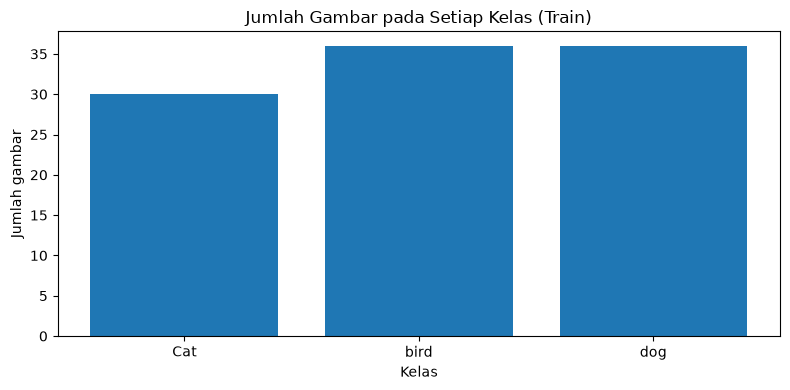

In [7]:
plt.figure(figsize=(8, 4))
plt.bar(train_counts.keys(), train_counts.values())
plt.title("Jumlah Gambar pada Setiap Kelas (Train)")
plt.xlabel("Kelas")
plt.ylabel("Jumlah gambar")
plt.tight_layout()
plt.show()

## 5. Menampilkan contoh citra dari setiap kelas

Bagian ini menampilkan beberapa gambar contoh dari ketiga kelas (Cat, Dog, dan Bird) pada folder training. Gambar diperlihatkan dalam bentuk aslinya sebelum dimasukkan ke proses pemuatan data dan augmentasi, sehingga isi serta variasi gambar dapat diperiksa secara langsung.

Pemeriksaan visual membantu memastikan file yang terbaca memang sesuai dengan label foldernya. Perhatikan juga apakah gambar dapat dibuka dengan baik, apakah objek terlihat jelas, dan apakah terdapat variasi latar belakang, ukuran objek, atau pencahayaan.

### Menampilkan sampel gambar
Fungsi `show_samples` memilih beberapa file gambar secara acak dari setiap kelas lalu menampilkannya dalam susunan subplot. Jumlah contoh per kelas diatur melalui parameter `samples_per_class`. Jika satu kelas hanya memiliki sedikit gambar atau gambar tidak dapat dibaca, perhatikan pesan atau tampilan yang dihasilkan dan periksa kembali file dataset tersebut.

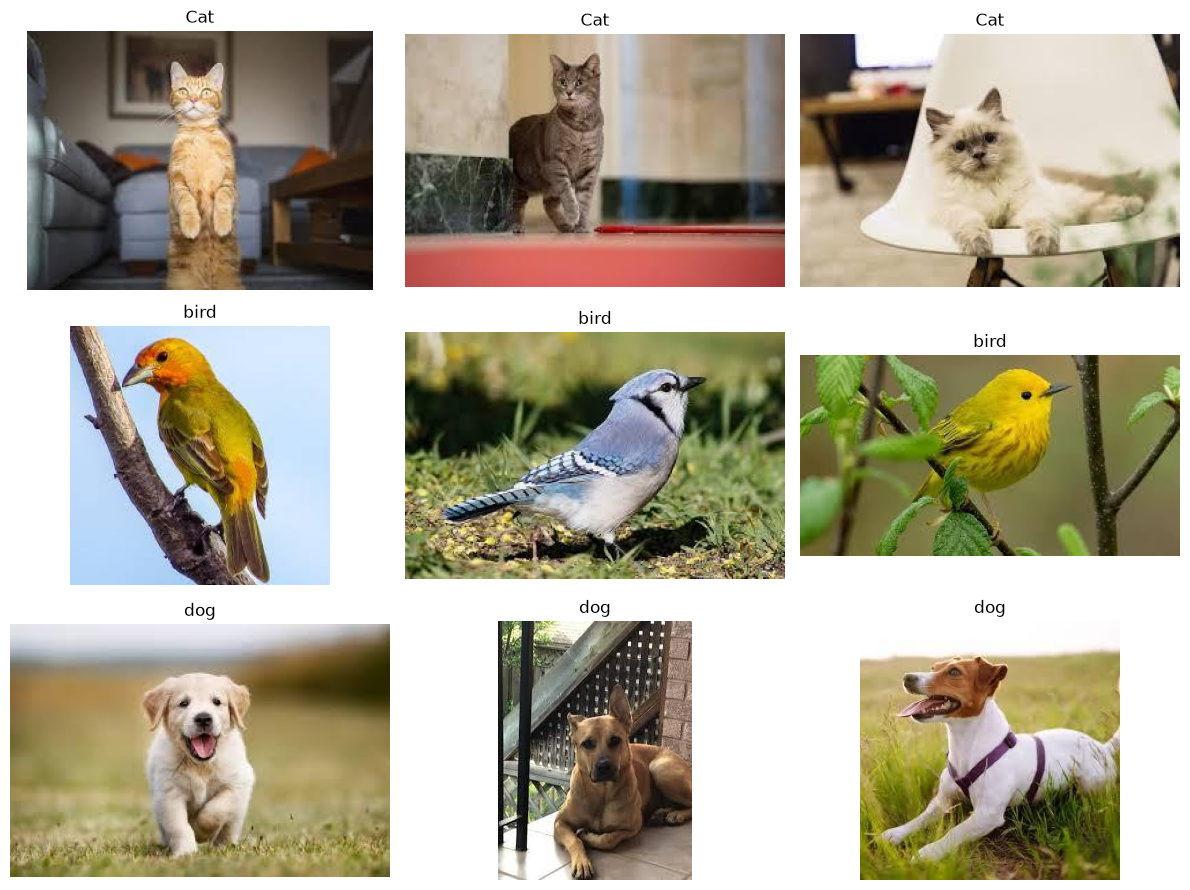

In [8]:
def show_samples(split_dir, class_names, samples_per_class=3):
    rows = len(class_names)
    fig, axes = plt.subplots(rows, samples_per_class, figsize=(4 * samples_per_class, 3 * rows))
    if rows == 1:
        axes = np.array([axes])
    for row, class_name in enumerate(class_names):
        image_files = [p for p in (split_dir / class_name).rglob("*")
                       if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
        for col in range(samples_per_class):
            ax = axes[row, col]
            if col < len(image_files):
                img = tf.keras.utils.load_img(image_files[col])
                ax.imshow(img)
                ax.set_title(class_name)
            ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(TRAIN_DIR, class_names)

## 6. Menyiapkan gambar untuk model

Agar gambar dapat diproses bersama-sama, semua citra diubah ke ukuran yang sama, yaitu 128 × 128 piksel. Pengaturan `BATCH_SIZE = 32` berarti model menerima hingga 32 gambar dalam satu batch. Fungsi `image_dataset_from_directory` membaca gambar berdasarkan subfolder dan membuat label angka untuk setiap kelas.

Parameter `label_mode="int"` menghasilkan label berbentuk bilangan bulat, sedangkan `shuffle=True` mengacak urutan gambar training. Dataset validasi dan evaluasi dibaca dengan urutan yang sesuai untuk pengukuran kinerja. Selanjutnya, layer `Rescaling(1./255)` pada model mengubah nilai piksel dari rentang 0–255 menjadi rentang 0–1. Normalisasi ini membantu menjaga skala masukan tetap konsisten.

### Membaca gambar dan membuat dataset
Sel ini menetapkan ukuran gambar 128 × 128 piksel dan ukuran batch 32. Fungsi `image_dataset_from_directory` membaca gambar berdasarkan nama subfolder kelas dan menghasilkan pasangan gambar-label. Data training diacak, sedangkan data validasi dan evaluasi disiapkan untuk mengukur kinerja model. Nama kelas yang terdeteksi juga disimpan agar urutan label dapat digunakan secara konsisten saat membuat confusion matrix dan laporan klasifikasi.

In [9]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)
valid_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

if TEST_DIR:
    eval_ds = tf.keras.utils.image_dataset_from_directory(
        TEST_DIR,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="int",
        shuffle=False
    )
else:
    eval_ds = valid_ds

class_names = train_ds.class_names
num_classes = len(class_names)
print("Urutan label:", class_names)

normalization = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization(x), y))
valid_ds = valid_ds.map(lambda x, y: (normalization(x), y))
eval_ds = eval_ds.map(lambda x, y: (normalization(x), y))

Found 102 files belonging to 3 classes.
Found 29 files belonging to 3 classes.
Found 16 files belonging to 3 classes.
Urutan label: ['Cat', 'bird', 'dog']


## 7. Data augmentation

Augmentasi membuat variasi tambahan dari gambar training melalui transformasi acak. Program menggunakan `RandomFlip("horizontal")` untuk membalik gambar secara mendatar, `RandomRotation(0.08)` untuk memberikan rotasi kecil, dan `RandomZoom(0.10)` untuk memperbesar atau memperkecil tampilan gambar secara acak.

Transformasi ini dilakukan ketika model sedang dilatih, bukan untuk mengubah file asli di dalam dataset. Tujuannya agar model tidak hanya menghafal posisi objek pada gambar training dan dapat belajar mengenali objek dalam variasi tampilan yang sedikit berbeda. Bagian visualisasi di sel ini memperlihatkan contoh gambar setelah augmentasi diterapkan.

### Membuat dan melihat augmentasi
Objek `data_augmentation` menggabungkan flip horizontal, rotasi ringan, dan zoom acak. Transformasi diterapkan secara acak saat data masuk ke model sehingga satu gambar dapat terlihat sedikit berbeda pada proses training yang berbeda. Bagian visualisasi di bawahnya menampilkan contoh hasil transformasi, sehingga pengaruh augmentasi dapat diperiksa sebelum model dilatih.

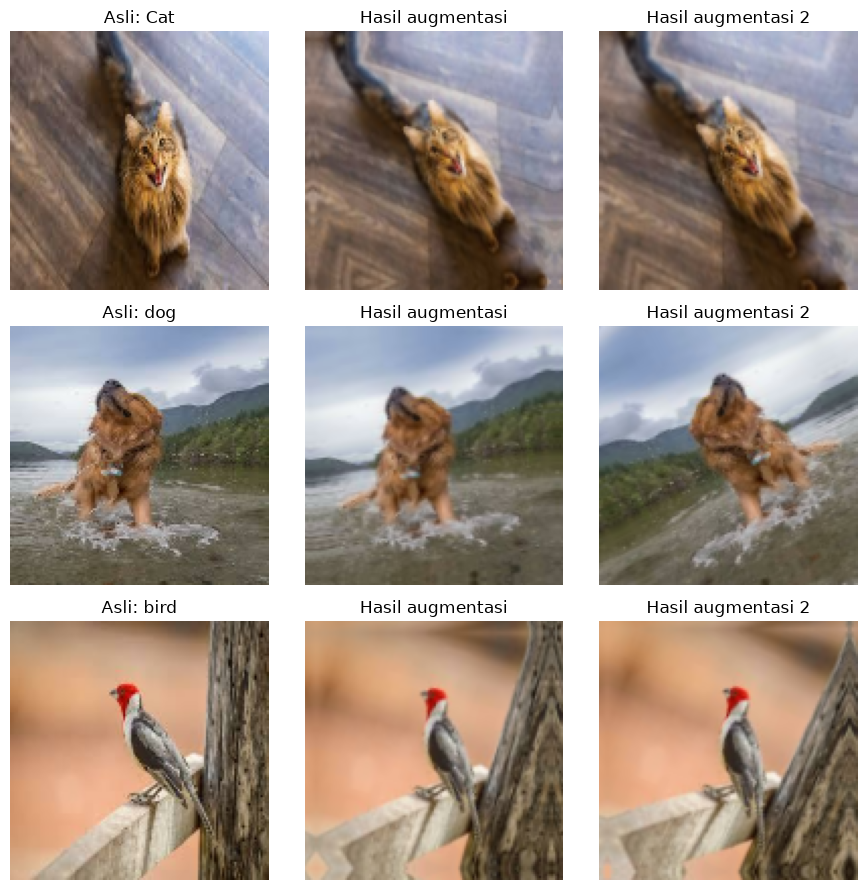

In [10]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10)
], name="data_augmentation")

# Tampilkan contoh gambar hasil augmentasi dari setiap kelas yang tersedia.
shown = set()
max_rows = min(len(class_names), 5)
fig, axes = plt.subplots(max_rows, 3, figsize=(9, 3 * max_rows))
if max_rows == 1:
    axes = np.array([axes])

for images, labels in train_ds.unbatch().batch(1):
    class_id = int(labels[0].numpy())
    if class_id in shown:
        continue
    shown.add(class_id)
    row = len(shown) - 1
    original = images[0].numpy()
    augmented = data_augmentation(images, training=True)[0].numpy()
    axes[row, 0].imshow(np.clip(original, 0, 1))
    axes[row, 0].set_title(f"Asli: {class_names[class_id]}")
    axes[row, 1].imshow(np.clip(augmented, 0, 1))
    axes[row, 1].set_title("Hasil augmentasi")
    augmented2 = data_augmentation(images, training=True)[0].numpy()
    axes[row, 2].imshow(np.clip(augmented2, 0, 1))
    axes[row, 2].set_title("Hasil augmentasi 2")
    for ax in axes[row]:
        ax.axis("off")
    if len(shown) >= max_rows:
        break

plt.tight_layout()
plt.show()

## 8. Menyiapkan aliran data

Setelah dataset dibuat, `prefetch` digunakan agar data untuk batch berikutnya dapat disiapkan ketika model sedang memproses batch saat ini. `tf.data.AUTOTUNE` membiarkan TensorFlow menyesuaikan jumlah proses persiapan data secara otomatis.

Langkah ini tidak mengubah label maupun isi kelas. Pengaturan tersebut bertujuan membuat aliran data lebih efisien selama pelatihan dan evaluasi, terutama ketika proses membaca gambar membutuhkan waktu.

### Mengaktifkan prefetch
`tf.data.AUTOTUNE` membiarkan TensorFlow menentukan pengaturan prefetch yang sesuai. `prefetch` diterapkan pada data training, validasi, dan evaluasi agar batch berikutnya dapat disiapkan lebih awal. Langkah ini membantu kelancaran aliran data dan tidak mengubah isi gambar, label, atau pembagian kelas.

In [11]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
valid_ds = valid_ds.prefetch(AUTOTUNE)
eval_ds = eval_ds.prefetch(AUTOTUNE)

## 9. Membangun arsitektur CNN custom

Model dibuat dengan `tf.keras.Sequential`, sehingga layer diproses secara berurutan. Masukan model berupa gambar RGB berukuran 128 × 128 piksel. Layer augmentasi memberi variasi pada gambar training, lalu `Rescaling` menormalkan nilai piksel.

Beberapa pasangan `Conv2D` dan `MaxPooling2D` digunakan untuk mempelajari pola visual. `Conv2D` mendeteksi ciri seperti tepi, tekstur, dan bentuk, sedangkan aktivasi `ReLU` membantu model mempelajari hubungan nonlinier. `MaxPooling2D` mengecilkan ukuran feature map agar komputasi lebih ringan. Setelah itu, `Flatten` mengubah feature map menjadi vektor, `Dense` mempelajari kombinasi fitur untuk membedakan kelas, dan layer keluaran menghasilkan skor probabilitas untuk tiga kategori gambar.

### Menyusun model CNN
Sel ini merangkai seluruh layer model secara berurutan. Layer masukan menerima tiga kanal warna RGB, lalu augmentasi dan normalisasi menyiapkan gambar. Layer konvolusi mempelajari fitur visual, pooling mengurangi dimensi fitur, dan layer dense mengolah fitur untuk menentukan kelas. Layer keluaran disesuaikan dengan jumlah kelas yang ditemukan dari dataset. Setelah model dibuat, ringkasan arsitektur dapat diperiksa untuk melihat bentuk keluaran dan jumlah parameter setiap layer.

In [12]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    data_augmentation,

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,067 (16.36 MB)

 Trainable params: 4,288,067 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

## 10. Melatih model

Model dilatih menggunakan data training dan diperiksa secara berkala menggunakan data validasi. `EPOCHS` menentukan batas maksimum putaran pelatihan. Dalam setiap epoch, model mempelajari pola dari data training, kemudian menghitung kinerja pada data validasi.

Dua callback membantu mengendalikan proses. `EarlyStopping` menghentikan pelatihan jika nilai `val_loss` tidak membaik selama beberapa epoch dan mengembalikan bobot terbaik yang tercatat. `ModelCheckpoint` menyimpan model dengan nilai `val_loss` terbaik ke file `cnn_custom_best.keras`. Karena pelatihan dapat berhenti lebih awal, jumlah epoch yang benar-benar dijalankan bisa lebih sedikit daripada batas maksimum.

### Menjalankan pelatihan
Sel ini menyiapkan callback, menentukan batas maksimum epoch, kemudian memanggil `model.fit`. Data training digunakan untuk memperbarui bobot, sementara `validation_data` digunakan untuk memantau performa pada data yang tidak dipakai memperbarui bobot. `EarlyStopping` membantu menghentikan pelatihan ketika loss validasi tidak membaik, dan `ModelCheckpoint` menyimpan model terbaik. Catatan akurasi dan loss dari setiap epoch disimpan di variabel `history` untuk dibuat grafiknya.

In [13]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "cnn_custom_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

EPOCHS = 15
history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/15


/Users/renayaputri81gmail.com/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.2843 - loss: 1.5286
Epoch 1: val_loss improved from None to 1.45383, saving model to cnn_custom_best.keras

Epoch 1: finished saving model to cnn_custom_best.keras
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 202ms/step - accuracy: 0.2843 - loss: 1.5286 - val_accuracy: 0.2759 - val_loss: 1.4538
Epoch 2/15
3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.3854 - loss: 1.1501
Epoch 2: val_loss improved from 1.45383 to 1.08972, saving model to cnn_custom_best.keras

Epoch 2: finished saving model to cnn_custom_best.keras
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.3725 - loss: 1.1481 - val_accuracy: 0.4483 - val_loss: 1.0897
Epoch 3/15
3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.3021 - loss: 1.0982
Epoch 3: val_loss did not improve from 1.08972
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.2941 - loss: 1.0985 - val_accuracy: 0.2414 - val_loss: 1.1040
Epoch 4/15
3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.3646 - loss: 

## 11. Melihat grafik akurasi dan loss

Riwayat pelatihan dari objek `history` disusun menjadi tabel menggunakan `Pandas`, lalu divisualisasikan menjadi dua grafik. Grafik akurasi membandingkan kemampuan prediksi pada data training dan validasi, sedangkan grafik loss memperlihatkan besar kesalahan model pada kedua kelompok data.

Akurasi yang meningkat biasanya menunjukkan prediksi semakin tepat, sementara loss yang menurun menunjukkan kesalahan model berkurang. Jika akurasi training terus meningkat tetapi akurasi validasi tertinggal atau loss validasi meningkat, model mungkin mengalami overfitting. Penilaian tetap perlu dilakukan dengan melihat kedua grafik secara bersamaan.

### Menggambar grafik pelatihan
Riwayat yang tersimpan di `history.history` diubah menjadi DataFrame agar nilai tiap epoch mudah diakses. Grafik pertama membandingkan akurasi training dengan validasi, sedangkan grafik kedua membandingkan loss keduanya. Sumbu horizontal menunjukkan epoch. Grafik ini digunakan untuk menilai apakah model terus belajar dan apakah performanya pada data validasi mengikuti performa training.

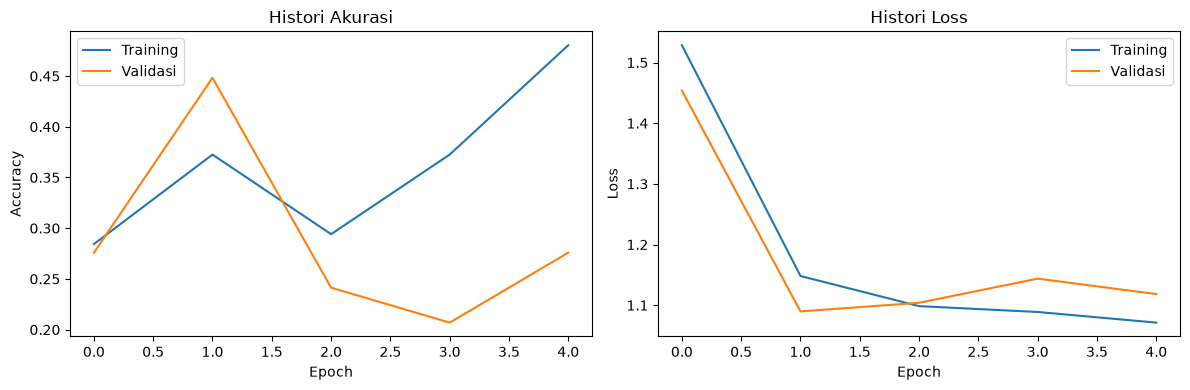

In [14]:
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["accuracy"], label="Training")
axes[0].plot(history_df["val_accuracy"], label="Validasi")
axes[0].set_title("Histori Akurasi")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history_df["loss"], label="Training")
axes[1].plot(history_df["val_loss"], label="Validasi")
axes[1].set_title("Histori Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## 12. Mengevaluasi hasil klasifikasi

Model klasifikasi tiga kelas (Cat, Dog, dan Bird) dievaluasi menggunakan folder test jika tersedia. Jika dataset tidak memiliki folder test, program menggunakan data validasi dan hasilnya perlu dipahami sebagai evaluasi pada data validasi, bukan data test terpisah.

`model.evaluate` menghasilkan nilai loss dan akurasi. Setelah itu, model membuat prediksi untuk gambar evaluasi. `confusion_matrix` membandingkan label sebenarnya dengan label prediksi; nilai pada diagonal menunjukkan prediksi yang benar, sedangkan nilai di luar diagonal menunjukkan kelas yang tertukar. `classification_report` menampilkan precision, recall, F1-score, dan support untuk tiap kelas. Metrik-metrik ini membantu melihat apakah model bekerja cukup seimbang pada Cat, Dog, dan Bird.

### Menghitung metrik evaluasi
Sel ini menghitung loss dan akurasi pada dataset evaluasi, lalu mengumpulkan label sebenarnya dan menghasilkan prediksi model. `argmax` memilih indeks kelas dengan skor prediksi tertinggi. Label sebenarnya dan hasil prediksi kemudian digunakan untuk membuat confusion matrix serta classification report. Perhatikan urutan nama kelas yang digunakan agar pembacaan baris dan kolom confusion matrix tidak tertukar.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.3125 - loss: 1.0914
Evaluation loss: 1.0914
Evaluation accuracy: 0.3125
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


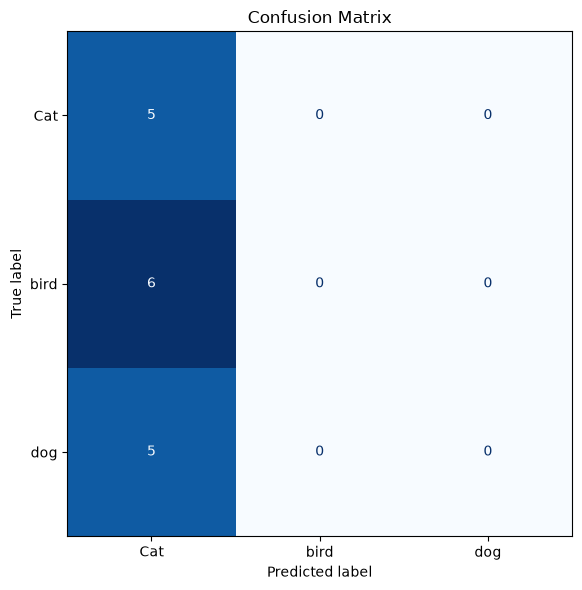

Classification Report:
              precision    recall  f1-score   support

         Cat       0.31      1.00      0.48         5
        bird       0.00      0.00      0.00         6
         dog       0.00      0.00      0.00         5

    accuracy                           0.31        16
   macro avg       0.10      0.33      0.16        16
weighted avg       0.10      0.31      0.15        16



In [15]:
eval_loss, eval_accuracy = model.evaluate(eval_ds, verbose=1)
print(f"Evaluation loss: {eval_loss:.4f}")
print(f"Evaluation accuracy: {eval_accuracy:.4f}")

y_true = np.concatenate([labels.numpy() for _, labels in eval_ds], axis=0)
y_prob = model.predict(eval_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(7, 6))
display.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

print("Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

## 13. Kesimpulan

Tuliskan kesimpulan setelah semua sel selesai dijalankan dan hasilnya sudah muncul. Jelaskan jumlah gambar pada setiap kelas, perubahan akurasi dan loss selama pelatihan, serta hasil evaluasi pada data yang digunakan.

Gunakan confusion matrix untuk menyebutkan kelas yang paling sering tertukar. Lalu, perhatikan precision, recall, dan F1-score untuk membandingkan kinerja model pada setiap kelas. Kesimpulan sebaiknya mengikuti angka yang benar-benar muncul dari notebook, bukan menggunakan nilai contoh atau perkiraan.

## 14. Menyimpan model

Model dengan nilai `val_loss` terbaik disimpan dalam file `cnn_custom_best.keras` oleh callback `ModelCheckpoint`. File ini berisi arsitektur dan bobot model sehingga dapat dimuat kembali untuk melakukan prediksi tanpa harus melatih model dari awal.

Pada lingkungan Google Colab, sel berikut mencoba mengunduh file model ke perangkat. Jika notebook dijalankan melalui VS Code atau Jupyter lokal, file tetap tersimpan di direktori kerja notebook dan dapat dipindahkan atau digunakan kembali sesuai kebutuhan.

### Mengunduh atau menyimpan file model
Sel ini mencoba mengenali apakah notebook dijalankan di Google Colab. Jika iya, file `cnn_custom_best.keras` ditawarkan untuk diunduh. Jika tidak, program menampilkan informasi bahwa file model tersimpan di direktori kerja lokal. Pastikan sel pelatihan berhasil membuat file tersebut sebelum menjalankan sel ini.

In [16]:
try:
    from google.colab import files
    files.download("cnn_custom_best.keras")
except ImportError:
    print("Model tersimpan di direktori kerja sebagai cnn_custom_best.keras")

Model tersimpan di direktori kerja sebagai cnn_custom_best.keras
